In [2]:
# ===== 抓取 2025 年 6 月整月数据（自包含，可单独运行）=====
from pathlib import Path
import pandas as pd
import pybaseball as pb
from pybaseball import cache

cache.enable()      # 开启本地缓存，重复运行不再联网

# 定位项目根目录（找 requirements.txt 所在的那一层）
def find_project_root(marker="requirements.txt"):
    p = Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / marker).exists():
            return c
    return p

ROOT = find_project_root()
print("项目根目录:", ROOT)

KEEP = ["game_date", "pitcher", "batter", "release_speed", "events", "launch_speed", "launch_angle",
        "game_pk", "game_type", "home_team", "away_team", "inning", "inning_topbot", "outs_when_up",
        "on_1b", "on_2b", "on_3b", "at_bat_number", "pitch_number", "description", "type", "bb_type",
        "stand", "p_throws", "bat_score", "post_bat_score", "post_home_score", "post_away_score"]

d = pb.statcast(start_dt="2025-06-01", end_dt="2025-06-30", verbose=True)

# 只保留存在的列，防止某些年份字段缺失导致 KeyError
d = d[[c for c in KEEP if c in d.columns]].copy()
d["game_date"] = pd.to_datetime(d["game_date"]).dt.strftime("%Y-%m-%d")

out = ROOT / "data" / "raw" / "2025-06_statcast_month.csv"
out.parent.mkdir(parents=True, exist_ok=True)      # 目录不存在则创建
d.to_csv(out, index=False, encoding="utf-8-sig")

print(f"已保存: {out}")
print(f"形状: {d.shape}  |  文件大小: {out.stat().st_size/1024/1024:.1f} MB")


项目根目录: C:\Users\GOOD\PycharmProjects\Baseball-Analytics
This is a large query, it may take a moment to complete


100%|██████████| 30/30 [00:00<00:00, 40.59it/s]


已保存: C:\Users\GOOD\PycharmProjects\Baseball-Analytics\data\raw\2025-06_statcast_month.csv
形状: (115816, 28)  |  文件大小: 11.1 MB


# 04 基于马尔可夫链的垒上局面转移矩阵

## 这一步做了什么
把棒球半局建模为马尔可夫链：24 个"出局数 × 跑垒员状态"的瞬态 + 1 个吸收态（半局结束）。
从逐球数据中统计相邻两次打席之间的状态转移频率，估计 24×24 的转移概率矩阵 P。
再用基本矩阵 (I − Q)^(-1) 从 P 推导每个状态的期望得分，与 Day 3 的经验值对照。

## 数据从哪来
- 输入：`data/raw/*_statcast.csv`（含 2025 年 6 月整月，约 3 万个打席）
- 每个打席的状态取该打席第一球之前的 `outs_when_up` 与三个垒位标记

## 结果是什么
- `data/processed/transition_matrix_24x24.csv`：行=起始状态，列=目标状态，行和为 1
- `figures/transition_matrix_heatmap.png`：转移概率热图
- `data/processed/re_markov_vs_empirical.csv`：马尔可夫推导值与经验值的逐状态对照

## 建模假设
1. 一阶马尔可夫：下一个状态只依赖当前状态，与之前的历史无关
2. 同质性：所有打席的转移规律相同，不区分打者水平、投手水平、球场
3. 这两个假设在棒球里都不完全成立，偏差留给后续 Day 处理


In [4]:
# ===== 环境、路径、状态编码 =====
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root(marker="requirements.txt"):
    p = Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / marker).exists():
            return c
    return p

ROOT = find_project_root()
PROC = ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)
FIG  = ROOT / "figures";            FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# 8 种垒位组合，顺序即 k = 0..7
BASE_ORDER = ["000", "100", "010", "001", "110", "101", "011", "111"]
BASE_INDEX = {b: i for i, b in enumerate(BASE_ORDER)}
BASE_LABEL = {"000":"空垒","100":"一垒","010":"二垒","001":"三垒",
              "110":"一二垒","101":"一三垒","011":"二三垒","111":"满垒"}

N_TRANSIENT = 24
ABSORB = 24          # 吸收态编号

def state_label(s: int) -> str:
    """把状态编号翻译成可读标签，用于打印和画图"""
    if s == ABSORB:
        return "半局结束"
    return f"{s // 8}出局-{BASE_LABEL[BASE_ORDER[s % 8]]}"

print("状态数:", N_TRANSIENT + 1)
print("示例:", state_label(0), "|", state_label(11), "|", state_label(24))


状态数: 25
示例: 0出局-空垒 | 1出局-三垒 | 半局结束


In [5]:
# ===== 读取所有逐球文件并合并 =====
files = sorted((ROOT / "data" / "raw").glob("*_statcast*.csv"))
print("读入文件：")
for f in files:
    print(f"  {f.name}  ({f.stat().st_size/1024/1024:.1f} MB)")

df = pd.concat([pd.read_csv(f, low_memory=False) for f in files], ignore_index=True)
df["game_date"] = pd.to_datetime(df["game_date"])

# 同一场同一打席同一球序去重（单日文件与整月文件会重叠）
df = df.drop_duplicates(subset=["game_pk", "at_bat_number", "pitch_number"])

# 只保留常规赛
if "game_type" in df.columns:
    n_before = df["game_pk"].nunique()
    df = df[df["game_type"].fillna("R") == "R"]
    print(f"\n常规赛过滤：{n_before} → {df['game_pk'].nunique()} 场")

print("总行数:", len(df))
print("比赛场数:", df["game_pk"].nunique())


读入文件：
  2025-06-14_statcast.csv  (0.4 MB)
  2025-06_statcast_month.csv  (11.1 MB)

常规赛过滤：397 → 397 场
总行数: 115816
比赛场数: 397


In [6]:
# ===== 打席层面：每个打席一行，记录起始状态、结束状态、本打席得分 =====
for b in ["on_1b", "on_2b", "on_3b"]:
    if f"has_{b}" not in df.columns:
        df[f"has_{b}"] = df[b].notna().astype(int)

HALF = ["game_pk", "inning", "inning_topbot"]

df = df.sort_values(HALF + ["at_bat_number", "pitch_number"])
df["bat_score"] = df["bat_score"].fillna(0)
df["post_bat_score"] = df.groupby(HALF)["post_bat_score"].ffill()

# 每个打席取第一球所在行：该行的 outs_when_up / 垒位就是"打席开始前"的状态
pa = df.drop_duplicates(subset=["game_pk", "at_bat_number"], keep="first").copy()

pa["base"] = (pa["has_on_1b"].astype(int).astype(str)
              + pa["has_on_2b"].astype(int).astype(str)
              + pa["has_on_3b"].astype(int).astype(str))
pa["outs"] = pa["outs_when_up"].astype(int)

pa = pa.sort_values(HALF + ["at_bat_number"]).reset_index(drop=True)

g = pa.groupby(HALF, sort=False)
pa["next_bat_score"] = g["bat_score"].shift(-1)      # 下一个打席开始前的比分
pa["next_outs"]      = g["outs"].shift(-1)
pa["next_base"]      = g["base"].shift(-1)
pa["half_final"]     = g["post_bat_score"].transform("max")   # 本半局最终得分

pa["is_last"] = pa["next_bat_score"].isna()

# 本打席打出的分数：下一个打席开始的比分 − 本打席开始时的比分
pa["runs_on_pa"] = np.where(pa["is_last"],
                            pa["half_final"] - pa["bat_score"],
                            pa["next_bat_score"] - pa["bat_score"])
# 从本打席起到本局结束的总得分（用于和经验 RE 对照）
pa["runs_to_end"] = pa["half_final"] - pa["bat_score"]

# 起始状态编号
pa["s_from"] = pa["outs"] * 8 + pa["base"].map(BASE_INDEX)

# 目标状态编号：半局最后一个打席转移到吸收态
tmp = (pa["next_outs"] * 8 + pa["next_base"].map(BASE_INDEX)).fillna(0)
pa["s_to"] = np.where(pa["is_last"], ABSORB, tmp).astype(int)

# 合理性检查
print("打席数:", len(pa))
print("runs_on_pa 出现负数:", int((pa["runs_on_pa"] < 0).sum()), "（应为 0）")
print("runs_on_pa 最大值:", pa["runs_on_pa"].max(), "（单打席最高通常 4）")
print("状态编号范围:", pa["s_from"].min(), "~", pa["s_from"].max())
pa[["game_pk","inning","outs","base","s_from","s_to","runs_on_pa"]].head(8)


打席数: 30045
runs_on_pa 出现负数: 0 （应为 0）
runs_on_pa 最大值: 4.0 （单打席最高通常 4）
状态编号范围: 0 ~ 23


,game_pk,inning,outs,base,s_from,s_to,runs_on_pa
0,777291,1,0,000,0,8,0.0
1,777291,1,1,000,8,16,0.0
2,777291,1,2,000,16,24,0.0
3,777291,1,0,000,0,8,0.0
4,777291,1,1,000,8,16,0.0
5,777291,1,2,000,16,24,0.0
6,777291,2,0,000,0,8,0.0
7,777291,2,1,000,8,16,0.0


In [7]:
# ===== 转移计数 → 行归一化 → 转移矩阵 P =====
counts = np.zeros((25, 25), dtype=float)
np.add.at(counts, (pa["s_from"].to_numpy(), pa["s_to"].to_numpy()), 1)

row_sum = counts.sum(axis=1, keepdims=True)

P = np.divide(counts, row_sum,
              out=np.zeros_like(counts),
              where=row_sum > 0)     # 无观测的行先置 0

P[ABSORB, ABSORB] = 1.0            # 吸收态自环

# 检查：每个瞬态的行和应为 1
print("瞬态行和的最小值/最大值:",
      round(P[:24].sum(axis=1).min(), 6), "/", round(P[:24].sum(axis=1).max(), 6))

# 每个状态的观测数
obs = counts[:24].sum(axis=1).astype(int)
sparse = [(state_label(s), obs[s]) for s in range(24) if obs[s] < 30]
print(f"\n观测数少于 30 的状态：{len(sparse)} 个")
for name, n in sparse:
    print(f"  {name}: {n}")


瞬态行和的最小值/最大值: 1.0 / 1.0

观测数少于 30 的状态：0 个


In [8]:
# ===== 打印出现最频繁的转移，便于人工核对是否符合棒球常识 =====
rows = []
for s in range(24):
    for t in range(25):
        if counts[s, t] > 0:
            rows.append({
                "从": state_label(s),
                "到": state_label(t),
                "次数": int(counts[s, t]),
                "概率": round(P[s, t], 4),
            })
trans_df = pd.DataFrame(rows).sort_values("次数", ascending=False)

print("出现次数最多的 15 条转移：")
print(trans_df.head(15).to_string(index=False))

print("\n抽查：空垒 0 出局时的去向分布")
row0 = trans_df[trans_df["从"] == "0出局-空垒"].sort_values("概率", ascending=False)
print(row0[["到","次数","概率"]].to_string(index=False))


出现次数最多的 15 条转移：
      从       到   次数     概率
 0出局-空垒  1出局-空垒 5041 0.6881
 1出局-空垒  2出局-空垒 3670 0.6875
 2出局-空垒    半局结束 2953 0.6953
 0出局-空垒  0出局-一垒 1650 0.2252
 2出局-一垒    半局结束 1526 0.6896
 1出局-空垒  1出局-一垒 1272 0.2383
 1出局-一垒  2出局-一垒  975 0.4516
 2出局-空垒  2出局-一垒  974 0.2293
 0出局-一垒  1出局-一垒  753 0.4427
2出局-一二垒    半局结束  638 0.6996
 2出局-二垒    半局结束  605 0.6844
 1出局-一垒 1出局-一二垒  436 0.2019
 2出局-一垒 2出局-一二垒  370 0.1672
2出局-一三垒    半局结束  341 0.6889
 0出局-空垒  0出局-二垒  339 0.0463

抽查：空垒 0 出局时的去向分布
     到   次数     概率
1出局-空垒 5041 0.6881
0出局-一垒 1650 0.2252
0出局-二垒  339 0.0463
0出局-空垒  260 0.0355
0出局-三垒   35 0.0048
  半局结束    1 0.0001


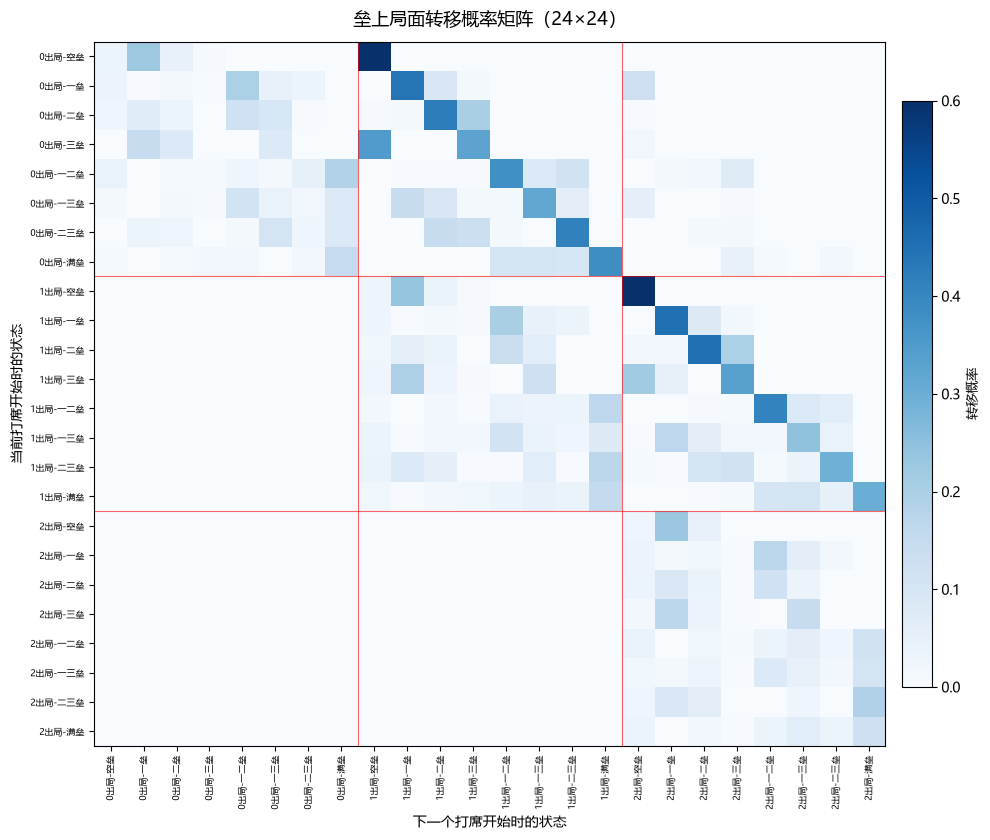

已保存: C:\Users\GOOD\PycharmProjects\Baseball-Analytics\figures\transition_matrix_heatmap.png


In [9]:
# ===== 转移矩阵热图 =====
fig, ax = plt.subplots(figsize=(10, 8.5), facecolor="white")
ax.set_facecolor("white")

im = ax.imshow(P[:24, :24], cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(24)); ax.set_yticks(range(24))
labels = [state_label(s) for s in range(24)]
ax.set_xticklabels(labels, rotation=90, fontsize=6.5)
ax.set_yticklabels(labels, fontsize=6.5)
ax.set_xlabel("下一个打席开始时的状态", fontsize=10)
ax.set_ylabel("当前打席开始时的状态", fontsize=10)
ax.set_title("垒上局面转移概率矩阵（24×24）", fontsize=13, pad=12)

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("转移概率", fontsize=9)

# 用横线分隔三个出局数区块
for k in [8, 16]:
    ax.axhline(k - 0.5, color="red", linewidth=0.8, alpha=0.6)
    ax.axvline(k - 0.5, color="red", linewidth=0.8, alpha=0.6)

fig.tight_layout()
out_fig = FIG / "transition_matrix_heatmap.png"
fig.savefig(out_fig, dpi=160, facecolor="white")
plt.show()
print("已保存:", out_fig)


## 用基本矩阵推导期望得分

把 24 个瞬态状态之间的转移写成子矩阵 $Q$（24×24），
每个状态一步的期望得分写成向量 $r$（24×1），
则每个状态到半局结束的期望总得分为

$$ \mathrm{RE} = (I - Q)^{-1} r $$

$(I-Q)^{-1}$ 称为基本矩阵 $N$，其元素 $N_{ij}$ 表示从状态 $i$ 出发、平均访问状态 $j$ 的次数。

这一步的意义：如果转移矩阵估计得准，那么用矩阵解出来的 RE 应当和 Day 3 直接用样本均值算出的 RE 接近。
两者吻合，说明"一阶马尔可夫"这个假设在本数据上没有明显违背；差距大，说明状态划分漏掉了信息。


In [10]:
# ===== 基本矩阵推导 RE，并与经验值对照 =====
r = np.zeros(25)
for s, gg in pa.groupby("s_from"):
    r[int(s)] = gg["runs_on_pa"].mean()

Q = P[:24, :24]
I = np.eye(24)

print("矩阵条件数:", round(np.linalg.cond(I - Q), 2), "（过大说明矩阵接近不可逆）")

Nmat = np.linalg.inv(I - Q)
re_markov = Nmat @ r[:24]

# 经验值：直接对 runs_to_end 求均值（Day 3 的做法）
re_emp = pa.groupby("s_from")["runs_to_end"].mean().reindex(range(24)).to_numpy()

cmp = pd.DataFrame({
    "state_id": range(24),
    "状态": [state_label(s) for s in range(24)],
    "样本量": obs,
    "RE_马尔可夫": np.round(re_markov, 3),
    "RE_经验值": np.round(re_emp, 3),
})
cmp["差值"] = (cmp["RE_马尔可夫"] - cmp["RE_经验值"]).round(3)

print("\n逐状态对照：")
print(cmp.to_string(index=False))

valid = cmp.dropna(subset=["RE_经验值"])
print(f"\n相关系数: {np.corrcoef(valid['RE_马尔可夫'], valid['RE_经验值'])[0,1]:.4f}")
print(f"平均绝对差: {valid['差值'].abs().mean():.4f}")
print(f"最大绝对差: {valid['差值'].abs().max():.4f}")


矩阵条件数: 5.33 （过大说明矩阵接近不可逆）

逐状态对照：
 state_id      状态  样本量  RE_马尔可夫  RE_经验值     差值
        0  0出局-空垒 7326    0.478   0.492 -0.014
        1  0出局-一垒 1701    0.853   0.857 -0.004
        2  0出局-二垒  503    1.070   0.960  0.110
        3  0出局-三垒   49    1.309   1.429 -0.120
        4 0出局-一二垒  426    1.449   1.477 -0.028
        5 0出局-一三垒  145    1.653   1.772 -0.119
        6 0出局-二三垒   85    1.806   1.929 -0.123
        7  0出局-满垒  115    2.101   2.087  0.014
        8  1出局-空垒 5338    0.258   0.270 -0.012
        9  1出局-一垒 2159    0.526   0.531 -0.005
       10  1出局-二垒  704    0.619   0.572  0.047
       11  1出局-三垒  210    0.924   0.814  0.110
       12 1出局-一二垒  785    0.913   0.913  0.000
       13 1出局-一三垒  332    1.170   1.196 -0.026
       14 1出局-二三垒  232    1.428   1.478 -0.050
       15  1出局-满垒  282    1.661   1.610  0.051
       16  2出局-空垒 4247    0.097   0.102 -0.005
       17  2出局-一垒 2213    0.228   0.237 -0.009
       18  2出局-二垒  884    0.300   0.294  0.006
       19  2出局-三垒  352    

In [11]:
# ===== 保存转移矩阵和对照表 =====
mat_df = pd.DataFrame(P[:25, :25],
                      index=[state_label(s) for s in range(25)],
                      columns=[state_label(s) for s in range(25)])
mat_df.to_csv(PROC / "transition_matrix_24x24.csv", encoding="utf-8-sig")

counts_df = pd.DataFrame(counts.astype(int),
                         index=[state_label(s) for s in range(25)],
                         columns=[state_label(s) for s in range(25)])
counts_df.to_csv(PROC / "transition_counts_24x24.csv", encoding="utf-8-sig")

cmp.to_csv(PROC / "re_markov_vs_empirical.csv", index=False, encoding="utf-8-sig")

print("已保存：")
for n in ["transition_matrix_24x24.csv", "transition_counts_24x24.csv", "re_markov_vs_empirical.csv"]:
    print("  data/processed/" + n)


已保存：
  data/processed/transition_matrix_24x24.csv
  data/processed/transition_counts_24x24.csv
  data/processed/re_markov_vs_empirical.csv


In [12]:
# ===== 文字结论 =====
best = cmp.dropna(subset=["RE_经验值"]).sort_values("RE_经验值").iloc[-1]
worst = cmp.dropna(subset=["RE_经验值"]).sort_values("RE_经验值").iloc[0]

print("=== Day 4 结论 ===")
print(f"样本：{df['game_pk'].nunique()} 场比赛，{len(pa)} 个打席")
print(f"转移矩阵 24×24，非零元 {(counts[:24,:24] > 0).sum()} 个，"
      f"占全部 {24*24} 个格子的 {(counts[:24,:24] > 0).sum()/(24*24):.1%}")
print(f"期望得分最高的状态：{best['状态']}，{best['RE_经验值']:.2f} 分")
print(f"期望得分最低的状态：{worst['状态']}，{worst['RE_经验值']:.2f} 分")
print(f"马尔可夫解与经验值相关系数 {np.corrcoef(valid['RE_马尔可夫'], valid['RE_经验值'])[0,1]:.3f}，"
      f"平均绝对差 {valid['差值'].abs().mean():.3f}")
print("\n下一日：用这套矩阵计算盗垒与短打的期望得分价值。")


=== Day 4 结论 ===
样本：397 场比赛，30045 个打席
转移矩阵 24×24，非零元 232 个，占全部 576 个格子的 40.3%
期望得分最高的状态：0出局-满垒，2.09 分
期望得分最低的状态：2出局-空垒，0.10 分
马尔可夫解与经验值相关系数 0.995，平均绝对差 0.040

下一日：用这套矩阵计算盗垒与短打的期望得分价值。
